# IDC detection models by Louis VINCENT

### Model 1

Imports

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

I0000 00:00:1792357669.612400    1625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792357669.613068    1625 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792357669.933351    1625 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792357671.631429    1625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONE

Creating the test and validation datasets

In [2]:
img_height = 50
img_width = 50

batch_size = 64
seed = 42
validation_split = 0.2

train_ds = tf.keras.utils.image_dataset_from_directory(
    "./breast-cancer",
    batch_size=batch_size,
    image_size=(img_height, img_width),
    seed=seed,
    validation_split=validation_split,
    subset="training"
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    "./breast-cancer",
    batch_size=batch_size,
    image_size=(img_height, img_width),
    seed=seed,
    validation_split=validation_split,
    subset="validation"
)

Found 275222 files belonging to 2 classes.
Using 220178 files for training.


E0000 00:00:1792357680.518133    1625 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792357680.518502    1843 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792357680.538239    1625 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Found 275222 files belonging to 2 classes.
Using 55044 files for validation.


Let's check the classes and visualize a sample of the images

In [3]:
class_names = train_ds.class_names
print(class_names)

['IDC', 'non-IDC']


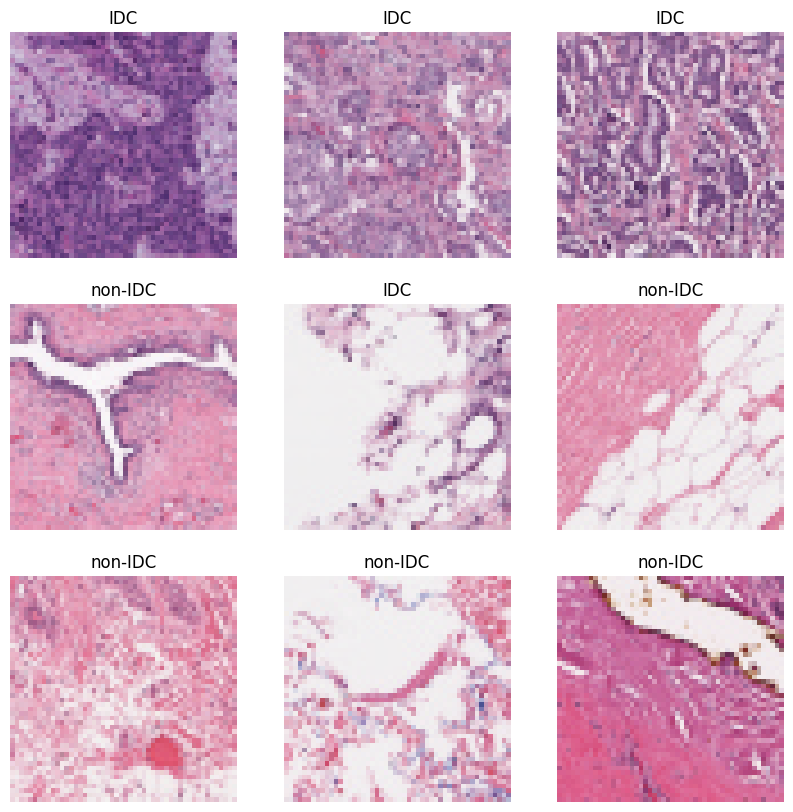

In [4]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

Defining the training sequence

In [ ]:
num_classes = 2  # len(train_batch.class_names)

model = tf.keras.Sequential(
    [
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(num_classes),
    ]
)

model.compile(
    optimizer="adam",
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

In [ ]:
history = model.fit(train_ds, validation_data=validation_ds, epochs=3)

In [ ]:
print(model.summary())

Plot the loss and the accuracy

In [ ]:
metrics = history.history
plt.plot(history.epoch, metrics["loss"], metrics["val_loss"])
plt.legend(["loss", "val_loss"])
plt.show()

plt.plot(history.epoch, metrics["accuracy"], metrics["val_accuracy"])
plt.legend(["accuracy", "val_accuracy"])
plt.show()

Show the prediction confusion matrix

In [ ]:
test_images = []
test_labels = []

for images, labels in validation_ds:
    for i in range(len(images)):
        test_images.append(images[i].numpy())
        test_labels.append(labels[i].numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

image_predictions = np.argmax(model.predict(test_images), axis=1)

In [ ]:
confusion_mtx = tf.math.confusion_matrix(test_labels, image_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(
    confusion_mtx,
    xticklabels=train_ds.class_names,
    yticklabels=train_ds.class_names,
    annot=True,
    fmt="g",
)
plt.xlabel("Prediction")
plt.ylabel("Label")
plt.show()